# Prototipo de Grafo de Ingredientes (GNN-Alimentos)
Este notebook es una prueba de concepto para demostrar cómo extraer la topología jerárquica de un producto a partir del JSON estructurado de GroceryDB. 

El objetivo es convertir el árbol de ingredientes en un grafo dirigido utilizando `networkx`, el cual servirá como base para crear el `edge_index` de PyTorch Geometric.

### 1. Importación de librerías y simulación de datos
Simulamos un producto extraído directamente de `UpdatedProductIngredients_11_15.json` para no saturar la memoria RAM en esta prueba inicial.

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# Simulamos la estructura exacta del JSON de GroceryDB
producto_ejemplo = {
    "product_name": "Galletas Ultraprocesadas de Ejemplo",
    "ingredient_tree": [
        {
            "ingredient_name": "harina de trigo enriquecida",
            "sub_ingredients": [
                {"ingredient_name": "harina de trigo", "sub_ingredients": []},
                {"ingredient_name": "niacina", "sub_ingredients": []},
                {"ingredient_name": "hierro", "sub_ingredients": []}
            ]
        },
        {
            "ingredient_name": "jarabe de maíz de alta fructosa",
            "sub_ingredients": []
        },
        {
            "ingredient_name": "conservadores artificiales",
            "sub_ingredients": [
                {"ingredient_name": "sorbato de potasio", "sub_ingredients": []},
                {"ingredient_name": "benzoato de sodio", "sub_ingredients": []}
            ]
        }
    ]
}

### 2. Construcción de la Topología (Nodos y Aristas)
Utilizamos una función recursiva para recorrer el árbol de ingredientes. 
* **Nodos:** Cada ingrediente o aditivo.
* **Aristas:** Conexiones dirigidas desde el ingrediente base hacia sus sub-ingredientes (padre $\rightarrow$ hijo).

In [3]:
# Inicializamos un grafo dirigido vacío
G = nx.DiGraph()

def construir_grafo(lista_ingredientes, nodo_padre=None):
    """
    Función recursiva que lee la lista de ingredientes anidados
    y crea las conexiones (aristas) en el grafo de NetworkX.
    """
    for ingrediente in lista_ingredientes:
        nombre_nodo = ingrediente["ingredient_name"]
        
        # Agregamos el ingrediente como nodo
        G.add_node(nombre_nodo)
        
        # Si existe un nodo padre, creamos la arista dirigida
        if nodo_padre:
            G.add_edge(nodo_padre, nombre_nodo)
            
        # Llamada recursiva si hay sub-ingredientes
        if "sub_ingredients" in ingrediente and len(ingrediente["sub_ingredients"]) > 0:
            construir_grafo(ingrediente["sub_ingredients"], nodo_padre=nombre_nodo)

# Ejecutamos la función creando un "Nodo Raíz" que representa al producto completo
G.add_node(producto_ejemplo["product_name"])
construir_grafo(producto_ejemplo["ingredient_tree"], nodo_padre=producto_ejemplo["product_name"])

print(f"Total de Nodos: {G.number_of_nodes()}")
print(f"Total de Aristas: {G.number_of_edges()}")
print("\nLista de Aristas (edge_index base):")
print(G.edges())

Total de Nodos: 9
Total de Aristas: 8

Lista de Aristas (edge_index base):
[('Galletas Ultraprocesadas de Ejemplo', 'harina de trigo enriquecida'), ('Galletas Ultraprocesadas de Ejemplo', 'jarabe de maíz de alta fructosa'), ('Galletas Ultraprocesadas de Ejemplo', 'conservadores artificiales'), ('harina de trigo enriquecida', 'harina de trigo'), ('harina de trigo enriquecida', 'niacina'), ('harina de trigo enriquecida', 'hierro'), ('conservadores artificiales', 'sorbato de potasio'), ('conservadores artificiales', 'benzoato de sodio')]


### 3. Visualización del Grafo
Dibujamos la red resultante para comprobar visualmente que la jerarquía se extrajo correctamente. Este árbol es exactamente lo que la Red Neuronal de Grafos (GNN) analizará para clasificar el alimento.

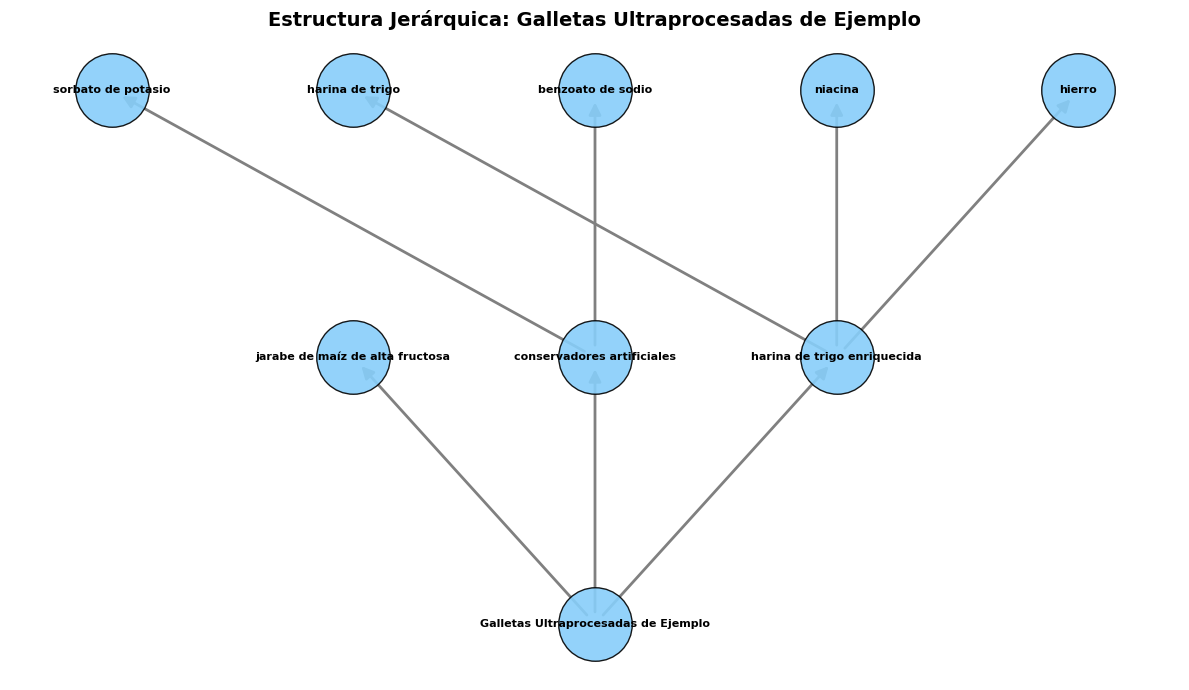

In [5]:
# Configuramos el lienzo
plt.figure(figsize=(12, 7))
plt.title(f"Estructura Jerárquica: {producto_ejemplo['product_name']}", fontsize=14, fontweight='bold')

# 1. Calculamos a qué distancia está cada ingrediente del nodo raíz (el producto)
for nodo in G.nodes():
    G.nodes[nodo]['capa'] = nx.shortest_path_length(G, source=producto_ejemplo['product_name'], target=nodo)

# 2. Usamos el layout "multipartito" para dibujarlos en columnas separadas por nivel jerárquico
pos = nx.multipartite_layout(G, subset_key="capa", align="horizontal")

# Dibujamos nodos, aristas y etiquetas
nx.draw_networkx_nodes(G, pos, node_color='#87CEFA', node_size=2800, alpha=0.9, edgecolors='black')
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=18, width=2)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold", font_family="sans-serif")

# Quitamos los ejes para que se vea más limpio
plt.axis('off')
plt.tight_layout()
plt.show()